# South and mainland Southeast Asia in EM-DAT, with detection

Does 13's model, fitted jointly over eleven countries from Pakistan to Vietnam, separate where climate-related events start from where EM-DAT records them, and which of India's results survive when detection and the hazard covariates' slopes are shared across reporting systems?

The record is EM-DAT's hydrometeorological and climatological events from 1990 to 2023 in Pakistan, India, Nepal, Bhutan, Bangladesh, Sri Lanka, Myanmar, Thailand, Laos, Cambodia and Vietnam, placed on GADM units as in 13. The model is 13's with one spatial field over the whole region, river size and coastline added to the hazard covariates, and the intercept, the year effect's coefficients and the overdispersion given to each country, since how many events EM-DAT records varies by country for reasons the hazard does not explain.

In [4]:
from pathlib import Path

import arviz as az
import geopandas as gpd
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import polars as pl
import pymc as pm
import pytensor.tensor as pt
import xarray as xr

from arviz_plots import PlotCollection

from climate_risk import load_shapefile
from climate_risk.data.gadm import administered_territories, load_units_in_country
from climate_risk.data.geo_disasters import load_resolved_units
from climate_risk.data.ghsl import population_on_cells
from climate_risk.data_functions.emdat_processing import DISASTER_CLASSES, event_geography, load_emdat_events
from climate_risk.data_functions.rivers_data_loader import load_rivers_data
from climate_risk.geo.crs import PROJECTED_CRS, to_km
from climate_risk.geo.distance import get_distance_to
from climate_risk.geo.raster import assign_cells_to_units, build_cell_grid, dissolve_place_boundary
from climate_risk.models.aggregation import Aggregation
from climate_risk.plotting import configure_plot_style

configure_plot_style()

CACHE_DIR = Path("../../data")
COUNTRIES = ("PAK", "IND", "NPL", "BTN", "BGD", "LKA", "MMR", "THA", "LAO", "KHM", "VNM")
SEED = 20261025

## Geography

Atoms are the cells of one 25 km lattice over the eleven countries. Each atom belongs to the ADM2, ADM1 and country covering most of it. A country's units include the territories GADM files apart from it under codes of its own, Kashmir's among them, and its ADM0 unit is the union of its ADM1 units.

In [2]:
RESOLUTION_KM = 25.0
LEVELS = ("ADM2", "ADM1", "ADM0")

# GADM files the territories a country administers in Kashmir and along its disputed borders under codes of their own.
codes_of = {iso: (iso, *administered_territories(iso, CACHE_DIR)) for iso in COUNTRIES}
units = {level: pd.concat([load_units_in_country(code, admin, CACHE_DIR).assign(country=iso) for iso, codes in codes_of.items() for code in codes],
                          ignore_index=True)
         for level, admin in [("ADM2", 2), ("ADM1", 1)]}
boundary = gpd.GeoDataFrame(pd.concat([dissolve_place_boundary(units["ADM1"].loc[units["ADM1"]["country"] == iso, ["geometry"]], iso3=iso) for iso in COUNTRIES],
                                      ignore_index=True))
units["ADM0"] = gpd.GeoDataFrame({"gid": list(COUNTRIES), "name": list(COUNTRIES), "admin_level": 0, "country": list(COUNTRIES)},
                                 geometry=boundary.geometry.to_numpy(),
                                 crs=boundary.crs)
grid = build_cell_grid(boundary, resolution_km=RESOLUTION_KM)
atoms = grid.cells.reset_index(drop=True)
n_atoms = len(atoms)
column_of_cell = pd.Series(np.arange(n_atoms), index=atoms["cell_id"].to_numpy())

# Every (atom, unit) pair that overlaps, with units as positions into units[level].
overlaps = {}
for level in LEVELS:
    pairs = assign_cells_to_units(grid, units[level])
    position = pd.Series(np.arange(len(units[level])), index=units[level]["gid"].to_numpy())
    overlaps[level] = pd.DataFrame({"atom": column_of_cell.loc[pairs["cell_id"]].to_numpy(),
                                    "unit": position.loc[pairs["gid"]].to_numpy(),
                                    "coverage": pairs["coverage"].to_numpy()})

# The unit covering most of each atom, which is the unit an event centered there is reported in.
unit_of_atom = {level: overlaps[level].sort_values("coverage", ascending=False).drop_duplicates("atom").set_index("atom")["unit"].reindex(np.arange(n_atoms)).to_numpy()
                for level in LEVELS}
n_units = {level: len(units[level]) for level in LEVELS}
unit_offset = dict(zip(LEVELS, np.cumsum([0, *[n_units[level] for level in LEVELS[:-1]]]), strict=True))
n_all_units = sum(n_units.values())
country_of_atom = unit_of_atom["ADM0"]
n_countries = len(COUNTRIES)

pd.DataFrame({
    "atoms": np.bincount(country_of_atom, minlength=n_countries),
    **{f"{level} units": units[level]["country"].value_counts().reindex(COUNTRIES, fill_value=0).to_numpy() for level in ("ADM2", "ADM1")},
    "territory codes": [", ".join(codes_of[iso][1:]) for iso in COUNTRIES],
}, index=list(COUNTRIES))

,atoms,ADM2 units,ADM1 units,territory codes
PAK,1620,32,8,Z06
IND,5402,676,41,"Z01, Z04, Z05, Z07, Z09"
NPL,278,14,5,
BTN,74,205,20,
BGD,250,64,8,
LKA,132,323,25,
MMR,1231,63,15,
THA,890,928,77,
LAO,368,142,18,
KHM,296,202,25,


## Covariates and population

The hazard covariates are four, each standardized over the region's atoms: the log distance from an atom to the nearest major river in HydroRIVERS, the log average discharge of that river, their product, and the log distance to the GSHHG shoreline. The product lets the effect of distance from a river depend on how large the river is. HydroRIVERS here holds reaches with an average discharge of at least 100 m3/s.

Each unit's detection covariate is its 2005 GHS-POP log population, standardized across the region's units of each level, so the shared naming curve reads a district of a given population the same way in every country. A unit's population is its coverage share of every atom it overlaps, which counts the people of units smaller than an atom.

In [5]:
COVARIATE_NAMES = ("log distance to river", "log discharge of nearest river", "distance by discharge", "log distance to coast")
# The nearest coast of an inland atom lies inside the region's bounds widened by this many degrees.
SHORELINE_MARGIN_DEGREES = 5.0


def standardized(values):
    """Values shifted to mean zero and scaled to unit standard deviation."""
    return (values - values.mean()) / values.std()


west, south, east, north = boundary.total_bounds
rivers = load_rivers_data(CACHE_DIR)
nearest_river = get_distance_to(rivers.cx[west - 1:east + 1, south - 1:north + 1], atoms, return_columns=["DIS_AV_CMS"])
river_km = to_km(nearest_river["distance_to_closest"].to_numpy())
river_discharge = nearest_river["DIS_AV_CMS"].to_numpy()
shoreline = load_shapefile("coastline", CACHE_DIR).boundary.clip((west - SHORELINE_MARGIN_DEGREES,
                                                                  south - SHORELINE_MARGIN_DEGREES,
                                                                  east + SHORELINE_MARGIN_DEGREES,
                                                                  north + SHORELINE_MARGIN_DEGREES))
coast_km = to_km(get_distance_to(shoreline[~shoreline.is_empty], atoms)["distance_to_closest"].to_numpy())

river_distance_z = standardized(np.log(river_km + 1.0))
discharge_z = standardized(np.log(river_discharge))
covariates = np.column_stack([river_distance_z,
                              discharge_z,
                              river_distance_z * discharge_z,
                              standardized(np.log(coast_km + 1.0))])

# Projected atom centers, scaled so the longer side of the region spans one unit, the domain the lengthscale prior is set on.
projected = atoms.to_crs(PROJECTED_CRS).geometry
atom_xy = np.column_stack([projected.x, projected.y])
DOMAIN_KM = to_km(np.ptp(atom_xy, axis=0).max())
atom_centroids = (atom_xy - atom_xy.min(axis=0)) / np.ptp(atom_xy, axis=0).max()

pd.concat([
    pd.DataFrame({"median": [np.median(river_km), np.median(river_discharge), np.median(coast_km)],
                  "max": [river_km.max(), river_discharge.max(), coast_km.max()]},
                 index=["river distance, km", "nearest river discharge, m3/s", "coast distance, km"]),
    pd.DataFrame(np.corrcoef(covariates.T), index=list(COVARIATE_NAMES), columns=list(COVARIATE_NAMES)),
]).round(2)

,median,max,log distance to river,log discharge of nearest river,distance by discharge,log distance to coast
"river distance, km",34.66,724.98,NaN,NaN,NaN,NaN
"nearest river discharge, m3/s",228.38,40395.23,NaN,NaN,NaN,NaN
"coast distance, km",320.30,1789.36,NaN,NaN,NaN,NaN
log distance to river,NaN,NaN,1.00,-0.07,0.18,-0.14
log discharge of nearest river,NaN,NaN,-0.07,1.00,0.01,0.10
distance by discharge,NaN,NaN,0.18,0.01,1.00,-0.00
log distance to coast,NaN,NaN,-0.14,0.10,-0.00,1.00


In [24]:
POPULATION_EPOCH = 2005

# A unit holds its coverage share of every atom it overlaps, so a unit smaller than an atom still holds its people.
population = population_on_cells(grid, POPULATION_EPOCH, CACHE_DIR)
unit_population = {level: np.bincount(overlaps[level]["unit"],
                                      weights=population[overlaps[level]["atom"]] * overlaps[level]["coverage"],
                                      minlength=n_units[level])
                   for level in LEVELS}
population_z = np.concatenate([standardized(np.log(np.maximum(unit_population[level], 1.0))) for level in LEVELS])

pd.DataFrame({f"median {level} population, thousands": pd.Series(unit_population[level]).groupby(units[level]["country"].to_numpy()).median().reindex(COUNTRIES) / 1e3
              for level in ("ADM2", "ADM1")}).round(0)

,"median ADM2 population, thousands","median ADM1 population, thousands"
PAK,4458.00,5971.00
IND,1370.00,9482.00
NPL,1802.00,5351.00
BTN,3.00,43.00
BGD,1871.00,15698.00
LKA,44.00,532.00
MMR,685.00,1832.00
THA,50.00,594.00
LAO,34.00,294.00
KHM,51.00,538.00


## The record

As in 13: EM-DAT's GADM coding first, Geo-Disasters for ground EM-DAT leaves unnamed, an event naming both levels reported at the coarser one, and an event naming nothing reported at its country's ADM0. EM-DAT files each event under one country, and a unit it names in another country, or in a territory another country administers, is dropped from the event's named set.

In [9]:
FIRST_YEAR, LAST_YEAR = 1990, 2023
LEVEL_OF_ADMIN = {2: "ADM2", 1: "ADM1"}

events = load_emdat_events(CACHE_DIR).filter(
    pl.col("ISO").is_in(list(COUNTRIES))
    & pl.col("Disaster Type").is_in(list(DISASTER_CLASSES))
    & pl.col("date").dt.year().is_between(FIRST_YEAR, LAST_YEAR)
)
resolved = pl.from_pandas(load_resolved_units(list(COUNTRIES), CACHE_DIR)).select(
    pl.col("DisNo."),
    pl.col("gid"),
    pl.col("name"),
    pl.col("admin_level").cast(pl.Int8),
    pl.col("geocoding_q").cast(pl.Int8),
    pl.col("overlap"),
)
geography = event_geography(events, resolved=resolved)

unit_position = {level: pd.Series(np.arange(n_units[level]), index=units[level]["gid"].to_numpy()) for level in ("ADM2", "ADM1")}
country_position = pd.Series(np.arange(n_countries), index=list(COUNTRIES))
# GADM gids nest, so district IND.15.3_1 lies in state IND.15_1. The version suffix can differ between levels, KHM.1.1_2 in KHM.1_1.
state_position_by_stem = pd.Series(np.arange(n_units["ADM1"]), index=units["ADM1"]["gid"].str.replace(r"_\d+$", "", regex=True).to_numpy())
state_of_district = state_position_by_stem.reindex(units["ADM2"]["gid"].str.replace(r"\.\d+_\d+$", "", regex=True)).to_numpy()


def named_units(rows, iso):
    """The units an event filed under ``iso`` names in that country, as positions into units[level], keyed by level."""
    named = {}
    for admin, gid in rows.filter(pl.col("gid").is_not_null()).select("admin_level", "gid").iter_rows():
        level = LEVEL_OF_ADMIN[admin]
        if gid in unit_position[level].index and units[level]["country"].iloc[unit_position[level].loc[gid]] == iso:
            named.setdefault(level, set()).add(int(unit_position[level].loc[gid]))

    return {level: tuple(sorted(found)) for level, found in named.items()}


def provinces_of(named):
    """Positions of the provinces an event names, directly or as the state of a named district, empty when it names neither."""
    return frozenset(named.get("ADM1", ())) | frozenset(state_of_district[list(named.get("ADM2", ()))].astype(int).tolist())


event_rows = []
dropped_units = 0
for (disno, iso), rows in geography.group_by("DisNo.", "ISO", maintain_order=True):
    named = named_units(rows, iso)
    dropped_units += rows.filter(pl.col("gid").is_not_null())["gid"].n_unique() - sum(len(found) for found in named.values())
    event_rows.append({
        "DisNo.": disno,
        "country": iso,
        "level": "ADM1" if "ADM1" in named else "ADM2" if named else "ADM0",
        "named": named or {"ADM0": (int(country_position[iso]),)},
        "provinces": provinces_of(named),
        "source": "+".join(sorted(set(rows["geometry_source"]))),
    })

record = pd.DataFrame(event_rows).merge(events.select("DisNo.", "Disaster Type", pl.col("date").dt.year().alias("year")).to_pandas(), on="DisNo.")

print(f"{dropped_units} named units outside the filing country dropped; districts with no state found: {int(np.isnan(state_of_district).sum())}")
record.groupby(["country", "level"]).size().unstack(fill_value=0).reindex(COUNTRIES).assign(events=lambda frame: frame.sum(axis=1))

139 named units outside the filing country dropped; districts with no state found: 0


level,ADM0,ADM1,ADM2,events
country,,,,
PAK,51,81,32,164
IND,15,283,154,452
NPL,6,8,66,80
BTN,2,4,1,7
BGD,33,29,148,210
LKA,3,28,59,90
MMR,2,29,24,55
THA,14,113,15,142
LAO,9,22,5,36


## The model

13's model, joint over the region. One Matern 3/2 field covers the region, with one basis function per 70 km of extent on each axis, the resolution 13 used over India, and a lengthscale prior with its mode at 340 km, as in 13. The covariate slopes, the naming curve and both offset scales are shared by every country.

Each country has its own intercept, so the field and the covariates explain where events start within and across countries after each country's overall level. Each country also has its own level probabilities, since GADM's ADM2 is a division of four million people in Pakistan and a gewog of a few thousand in Bhutan, and countries report across their levels in proportions of their own. Recorded events are counted by country and year, negative binomial around each country's annual mean, scaled by its own year effect: each country draws its own coefficients on one Matern 5/2 basis over years, with amplitude and lengthscale shared. The dispersion is each country's. A record's share is taken within its country, since a country's annual counts fix how many records it has.

In [30]:
HSGP_BOUNDARY_FACTOR = 4.0
HSGP_KM_PER_BASIS = 70.0
FIELD_LENGTHSCALE_MODE_KM = 340.0
YEAR_BOUNDARY_FACTOR = 1.5
YEAR_BASIS = 20
OFFSET_SD_PRIOR = 0.5
OFFSET_LEVELS = ("ADM2", "ADM1")
# A prior guess at the density of event centers over the whole record, recorded or not, which fixes where each intercept sits.
PRIOR_EVENT_CENTERS_PER_ATOM = 0.18
sample_kwargs = {
    "chains": 8,
    "cores": 8,
    "tune": 500,
    "draws": 250,
    "random_seed": SEED,
}

In [10]:
years = np.arange(FIRST_YEAR, LAST_YEAR + 1)
YEARS = len(years)
annual_observed = record.groupby(["country", "year"]).size().unstack(fill_value=0).reindex(index=list(COUNTRIES), columns=years, fill_value=0).to_numpy()
field_basis = np.ceil(to_km(np.ptp(atom_xy, axis=0)) / HSGP_KM_PER_BASIS).astype(int).tolist()
atom_country = np.eye(n_countries)[country_of_atom].T

# Each (level, atom) in one flat index, level-major, and the all-units index of the atom's unit at that level.
center_unit = np.concatenate([unit_offset[level] + unit_of_atom[level] for level in LEVELS])


def union_cells(named, country):
    """The (level, atom) cells of an event's union inside ``country``, the atoms its record's share is taken over, read at the level it is reported at."""
    level = "ADM1" if "ADM1" in named else next(iter(named))
    atoms_named = np.unique(np.concatenate([overlaps[at]["atom"][overlaps[at]["unit"].isin(found)].to_numpy() for at, found in named.items()]))
    atoms_named = atoms_named[country_of_atom[atoms_named] == country]

    return LEVELS.index(level), LEVELS.index(level) * n_atoms + atoms_named


record_key = record.apply(lambda event: (event["country"], tuple(sorted(event["named"].items()))), axis=1)
distinct = record.assign(key=record_key).groupby("key", sort=False).agg(multiplicity=("DisNo.", "size"), named=("named", "first"), country=("country", "first"))
distinct_country = country_position.loc[distinct["country"]].to_numpy()
cells_by_record = [union_cells(named, country) for named, country in zip(distinct["named"], distinct_country, strict=True)]
detection_terms = {
    "multiplicity": distinct["multiplicity"].to_numpy(),
    "country": distinct_country,
    "union": Aggregation(units=tuple(f"record {index}" for index in range(len(distinct))),
                         rows=np.repeat(np.arange(len(distinct)), [len(cells) for _, cells in cells_by_record]),
                         columns=np.concatenate([cells for _, cells in cells_by_record]),
                         weights=np.ones(sum(len(cells) for _, cells in cells_by_record)),
                         n_cells=len(LEVELS) * n_atoms),
}
COORDS = {
    "country": list(COUNTRIES),
    "covariate": list(COVARIATE_NAMES),
    "atom": np.arange(n_atoms),
    "unit": np.arange(n_all_units),
    "level": list(LEVELS),
    "record": detection_terms["union"].units,
    "year": years,
    "year_basis": np.arange(YEAR_BASIS),
    **{level: units[level]["gid"].to_list() for level in OFFSET_LEVELS},
}

pd.Series({
    "distinct records": len(distinct),
    "records whose union holds no atom of their country": sum(len(cells) == 0 for _, cells in cells_by_record),
})

distinct records                                      1127
records whose union holds no atom of their country       0
dtype: int64

In [25]:
def latent_log_rate():
    """The log rate of event centers at every atom, built inside the current model."""
    intercept = pm.Normal("intercept",
                          mu=np.log(PRIOR_EVENT_CENTERS_PER_ATOM),
                          sigma=1.0,
                          dims="country")
    slopes = pm.Normal("slopes",
                       mu=0.0,
                       sigma=1.0,
                       dims="covariate")

    # Mode at FIELD_LENGTHSCALE_MODE_KM, in units of the region's longer side.
    field_lengthscale = pm.InverseGamma("field_lengthscale",
                                        alpha=3.0,
                                        beta=4.0 * FIELD_LENGTHSCALE_MODE_KM / DOMAIN_KM)
    field_amplitude = pm.HalfNormal("field_amplitude", sigma=1.0)
    gp = pm.gp.HSGP(m=field_basis,
                    c=HSGP_BOUNDARY_FACTOR,
                    cov_func=field_amplitude**2 * pm.gp.cov.Matern32(input_dim=2, ls=field_lengthscale))
    field = gp.prior("field", X=atom_centroids, dims="atom")

    offset_part = 0.0
    for level in OFFSET_LEVELS:
        offset_sd = pm.HalfNormal(f"{level}_offset_sd", sigma=OFFSET_SD_PRIOR)
        standard = pm.Normal(f"{level}_offset_standard",
                             mu=0.0,
                             sigma=1.0,
                             dims=level)
        offsets = pm.Deterministic(f"{level}_offset", offset_sd * standard, dims=level)
        offset_part = offset_part + offsets[unit_of_atom[level]]

    return pm.Deterministic("log_rate",
                            intercept[country_of_atom] + pm.math.dot(covariates, slopes) + field + offset_part,
                            dims="atom")


def recorded_intensity():
    """Recorded events per (level, atom) over the record: centers, times the level's share in the atom's country, times detection by the center's unit there."""
    rate = pm.math.exp(latent_log_rate())
    naming_intercept = pm.Normal("naming_intercept",
                                 mu=0.0,
                                 sigma=1.5)
    naming_slope = pm.Normal("naming_slope",
                             mu=0.0,
                             sigma=1.0)
    naming = pm.Deterministic("naming_probability",
                              pm.math.invlogit(naming_intercept + naming_slope * population_z),
                              dims="unit")
    # GADM's levels are different kinds of unit in each country, so each country reports across them in its own proportions.
    level_probability = pm.Dirichlet("level_probability",
                                     a=np.ones((n_countries, len(LEVELS))),
                                     dims=("country", "level"))

    return level_probability[country_of_atom].T * rate[None, :] * naming[center_unit].reshape((len(LEVELS), n_atoms))


def annual_count(recorded_by_country, observed=None):
    """Recorded events in each country and year: negative binomial around the country's annual mean, scaled by its own smooth year effect."""
    # Mode at 5 years, so the effect follows changes in reporting over a few years and leaves single years to the dispersion.
    year_lengthscale = pm.InverseGamma("year_lengthscale",
                                       alpha=3.0,
                                       beta=20.0)
    year_amplitude = pm.HalfNormal("year_amplitude", sigma=0.5)
    gp = pm.gp.HSGP(m=[YEAR_BASIS],
                    c=YEAR_BOUNDARY_FACTOR,
                    cov_func=year_amplitude**2 * pm.gp.cov.Matern52(input_dim=1, ls=year_lengthscale))
    year_basis, year_sqrt_psd = gp.prior_linearized(X=years[:, None].astype(float))
    year_coefficients = pm.Normal("year_effect_coefficients",
                                  mu=0.0,
                                  sigma=1.0,
                                  dims=("country", "year_basis"))
    year_effect = pm.Deterministic("year_effect",
                                   (year_coefficients * year_sqrt_psd) @ year_basis.T,
                                   dims=("country", "year"))
    overdispersion = pm.HalfNormal("overdispersion",
                                   sigma=1.0,
                                   dims="country")

    return pm.NegativeBinomial("annual_count",
                               mu=recorded_by_country[:, None] / YEARS * pt.exp(year_effect),
                               alpha=1.0 / overdispersion[:, None],
                               observed=observed,
                               dims=("country", "year"))


def counted_logp(count, probability):
    """Log probability of ``count`` events sharing one record, given the record's probability under the model."""
    return count * pt.log(probability)


def build_event_detection_model():
    """The event likelihood with detection by the center's unit, and recorded counts by country that vary by year."""
    terms = detection_terms

    with pm.Model(coords=COORDS) as model:
        recorded = recorded_intensity()
        recorded_by_country = pm.Deterministic("recorded_rate",
                                               pt.dot(atom_country, recorded.sum(axis=0)),
                                               dims="country")

        annual_count(recorded_by_country, observed=annual_observed)
        # A country's year effect scales its whole map, so it cancels from each record's share of its country's recorded intensity.
        pm.CustomDist("record_count",
                      terms["union"].aggregate_symbolic(recorded.ravel()) / recorded_by_country[terms["country"]],
                      logp=counted_logp,
                      observed=terms["multiplicity"],
                      dims="record")

    return model


event_detection_model = build_event_detection_model()

pd.Series({
    "distinct records": len(distinct),
    "field basis per axis": str(field_basis),
    "largest union, atoms": int(np.bincount(detection_terms["union"].rows).max()),
    "free parameters": sum(value.size for value in event_detection_model.initial_point().values()),
})

distinct records            1127
field basis per axis    [77, 54]
largest union, atoms        5402
free parameters             8098
dtype: object

## Prior predictive

How many recorded events over 34 years the priors allow in each country before seeing the record.

Sampling: [ADM1_offset_sd, ADM1_offset_standard, ADM2_offset_sd, ADM2_offset_standard, annual_count, field_amplitude, field_hsgp_coeffs, field_lengthscale, intercept, level_probability, naming_intercept, naming_slope, overdispersion, slopes, year_amplitude, year_effect_coefficients, year_lengthscale]


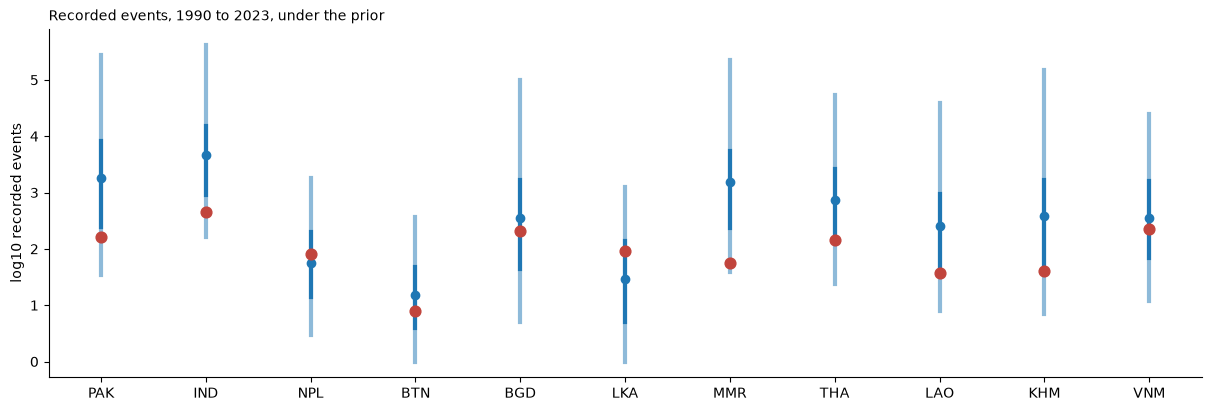

In [26]:
PRIOR_DRAWS = 1_000
OBSERVED_COLOR = "#c1443c"
OBSERVED_MARKERS = {"color": OBSERVED_COLOR, "marker": "o", "size": 60, "zorder": 4}

with event_detection_model:
    prior = pm.sample_prior_predictive(draws=PRIOR_DRAWS,
                                       var_names=["annual_count"],
                                       random_seed=SEED)

# Recorded counts span orders of magnitude under the prior, so they are compared as log10 of one plus the count.
prior_totals = xr.DataTree.from_dict({
    "prior_predictive": np.log10(prior["prior_predictive"]["annual_count"].sum("year") + 1).to_dataset(name="log10 recorded events"),
    "observed_data": xr.Dataset({"log10 recorded events": ("country", np.log10(annual_observed.sum(axis=1) + 1))}, coords={"country": list(COUNTRIES)}),
})
az.plot_ppc_interval(prior_totals,
                     group="prior_predictive",
                     visuals={"observed_markers": OBSERVED_MARKERS},
                     figure_kwargs={"figsize": (12, 4)})
axis = plt.gca()
axis.set_xticks(np.arange(n_countries), list(COUNTRIES))
axis.set_xlabel("")
axis.set_title("Recorded events, 1990 to 2023, under the prior", loc="left", fontsize=10)
plt.show()

## Fit

In [31]:
FIT_PATH = Path("fits/14_south_asia_nuts_country_levels.nc")

if FIT_PATH.exists():
    fit = az.from_netcdf(FIT_PATH)
else:
    with event_detection_model:
        fit = pm.sample(**sample_kwargs)
    # An interrupted run returns the draws it reached, which must not be cached as a fit.
    if fit.posterior.sizes["draw"] == sample_kwargs["draws"]:
        fit.to_netcdf(FIT_PATH)

NUTS[nutpie]: [intercept, slopes, field_lengthscale, field_amplitude, field_hsgp_coeffs, ADM2_offset_sd, ADM2_offset_standard, ADM1_offset_sd, ADM1_offset_standard, naming_intercept, naming_slope, level_probability, year_lengthscale, year_amplitude, year_effect_coefficients, overdispersion]


Output()

In [32]:
SUMMARY_VARIABLES = ["slopes", "field_amplitude", "field_lengthscale", "ADM2_offset_sd", "ADM1_offset_sd", "naming_intercept", "naming_slope", "level_probability", "year_amplitude", "year_lengthscale"]
every_free = az.summary(fit, var_names=[variable.name for variable in event_detection_model.free_RVs])

pd.concat([
    az.summary(fit, var_names=SUMMARY_VARIABLES),
    pd.DataFrame({"r_hat": [every_free["r_hat"].max()], "ess_bulk": [every_free["ess_bulk"].min()]}, index=["worst over every free parameter"]),
    pd.DataFrame({"mean": [int(fit.sample_stats["diverging"].sum())]}, index=["divergences"]),
]).round(2)

,mean,sd,eti89_lb,eti89_ub,ess_bulk,ess_tail,r_hat,mcse_mean,mcse_sd
slopes[log distance to river],-0.99,0.14,-1.21,-0.78,471.50,718.88,1.01,0.01,0.00
slopes[log discharge of nearest river],-0.39,0.21,-0.73,-0.06,325.90,445.33,1.02,0.01,0.01
slopes[distance by discharge],-0.37,0.13,-0.59,-0.17,395.13,607.17,1.02,0.01,0.00
slopes[log distance to coast],-0.63,0.16,-0.88,-0.39,349.49,562.22,1.02,0.01,0.00
field_amplitude,0.66,0.30,0.20,1.18,191.94,128.46,1.06,0.02,0.01
field_lengthscale,0.13,0.09,0.05,0.30,272.40,286.30,1.02,0.01,0.01
ADM2_offset_sd,2.31,0.17,2.04,2.59,233.42,395.60,1.04,0.01,0.01
ADM1_offset_sd,0.40,0.24,0.06,0.82,118.87,204.59,1.06,0.02,0.01
naming_intercept,-3.05,0.58,-3.94,-2.10,154.39,254.21,1.05,0.05,0.02
naming_slope,0.71,0.23,0.35,1.09,149.02,290.08,1.05,0.02,0.01


## Posterior against prior

Sampling: [ADM1_offset_sd, ADM2_offset_sd, field_amplitude, field_lengthscale, intercept, level_probability, naming_intercept, naming_slope, overdispersion, slopes, year_amplitude, year_lengthscale]


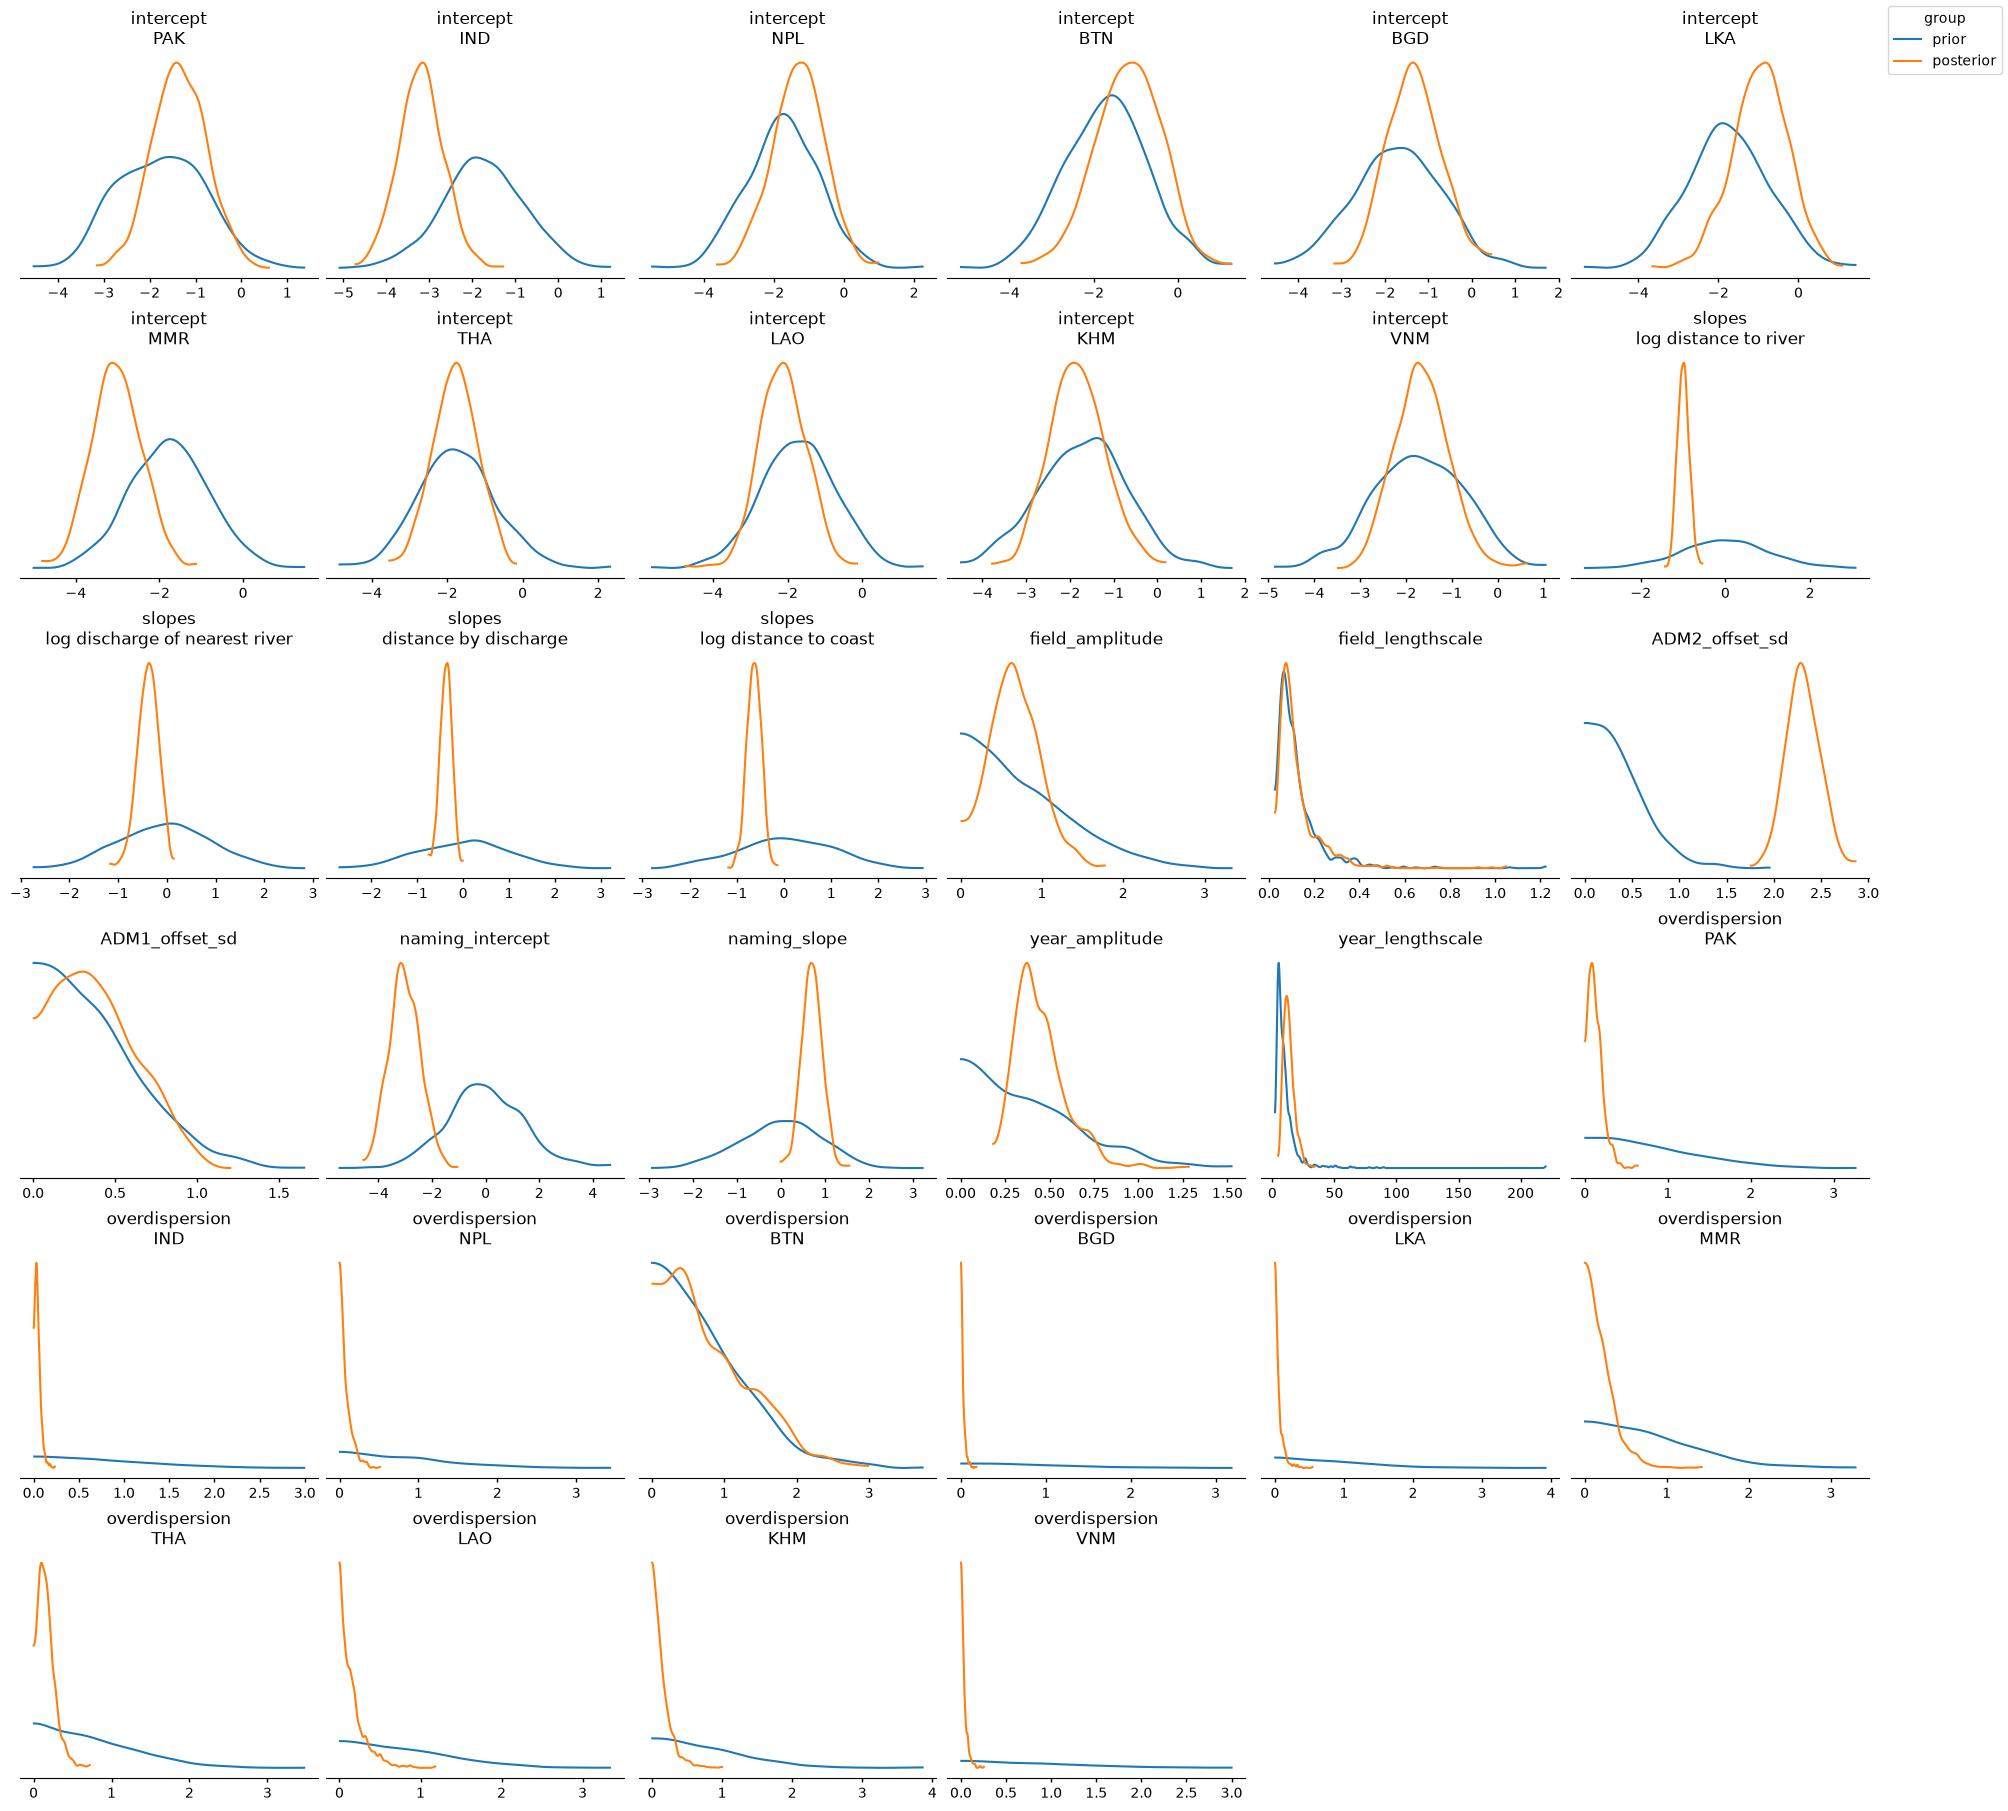

In [34]:
PARAMETERS = ["intercept", "slopes", "field_amplitude", "field_lengthscale", "ADM2_offset_sd", "ADM1_offset_sd", "naming_intercept", "naming_slope", "level_probability", "year_amplitude", "year_lengthscale", "overdispersion"]
# The level probabilities' 33 panels are read in the level split's predictive check instead.
PLOTTED_PARAMETERS = [name for name in PARAMETERS if name != "level_probability"]

with event_detection_model:
    fit["prior"] = pm.sample_prior_predictive(draws=PRIOR_DRAWS,
                                              var_names=PARAMETERS,
                                              random_seed=SEED)["prior"]

az.plot_prior_posterior(fit,
                        var_names=PLOTTED_PARAMETERS,
                        col_wrap=6,
                        figure_kwargs={"figsize": (20, 18)})
plt.show()

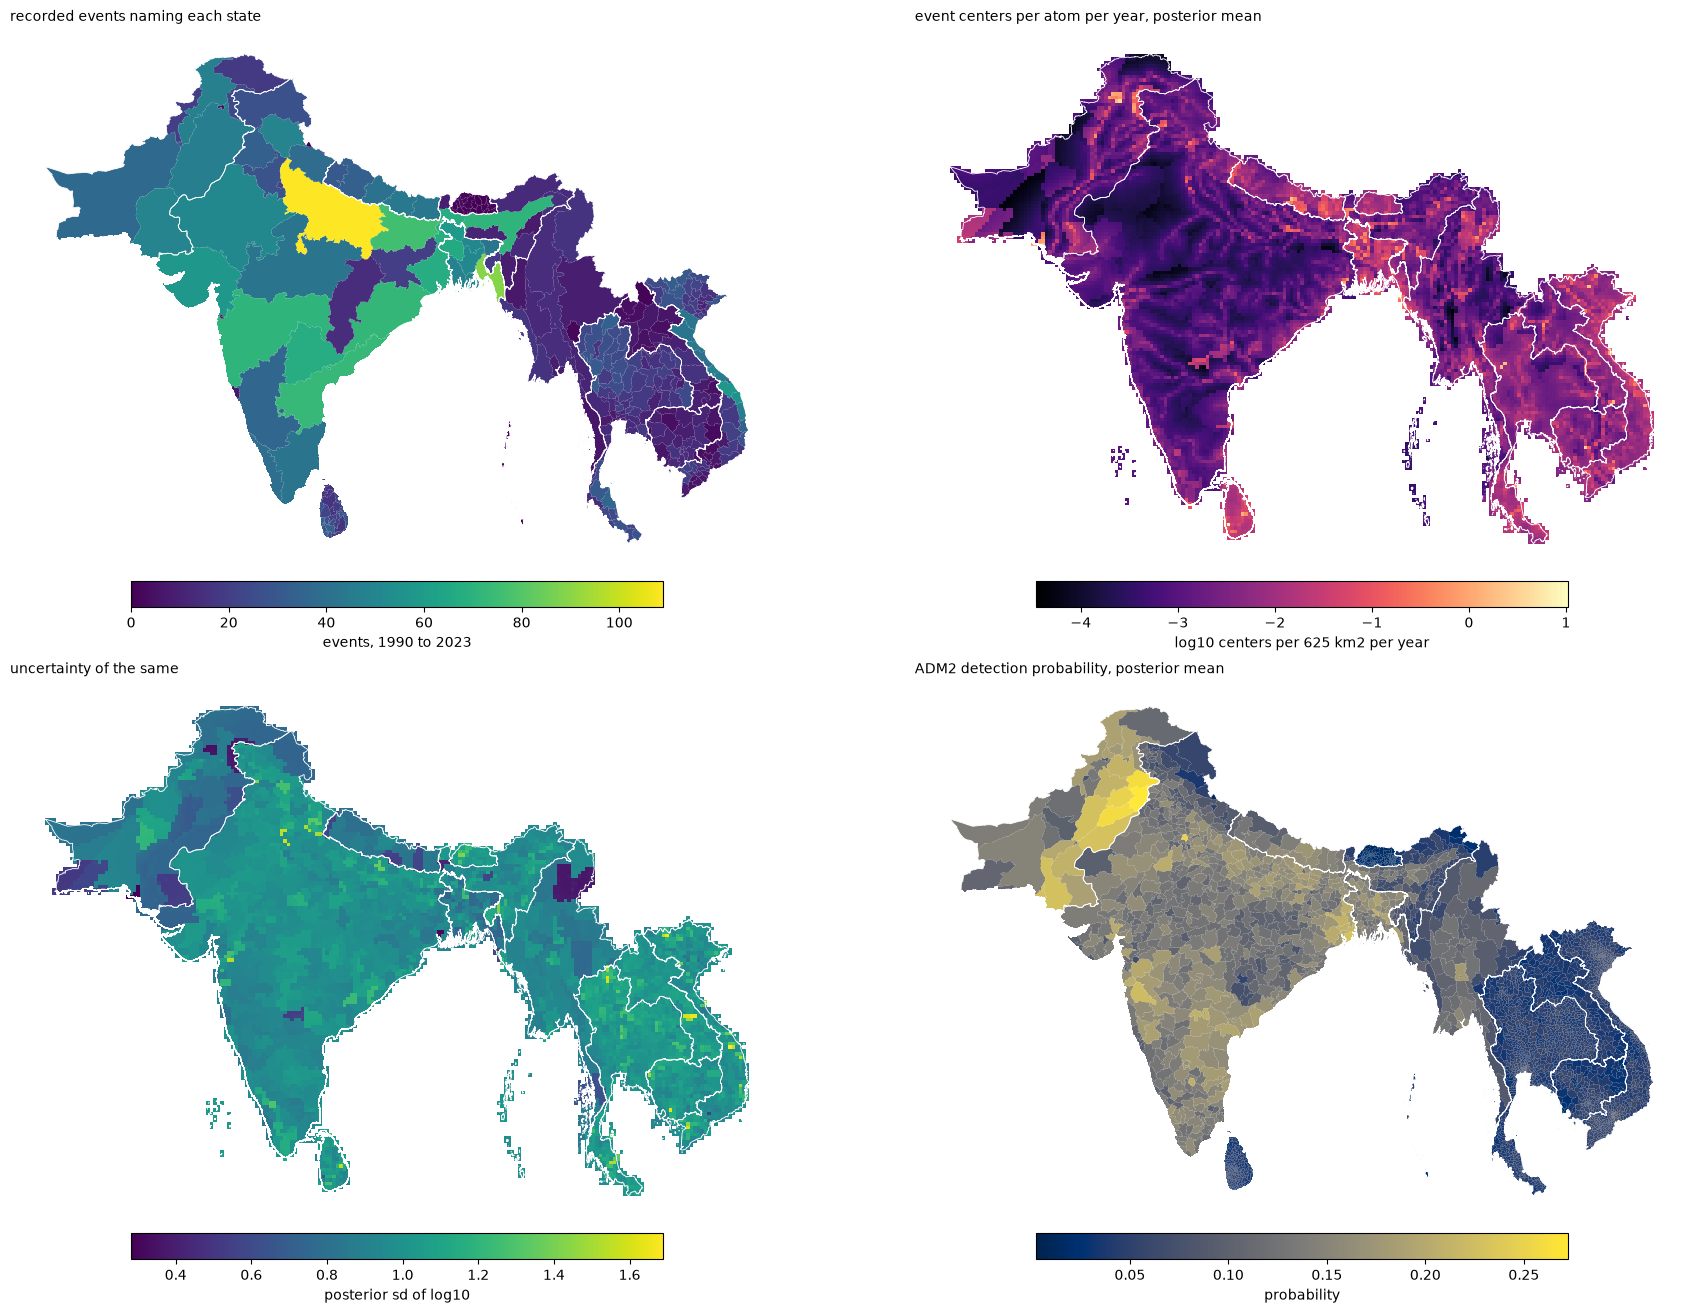

In [35]:
posterior = fit.posterior
adm2_units = slice(unit_offset["ADM2"], unit_offset["ADM2"] + n_units["ADM2"])
atom_cells = gpd.GeoDataFrame(geometry=grid.footprints.reset_index(drop=True), crs=grid.footprints.crs)
country_borders = units["ADM0"].boundary

log10_annual = (posterior["log_rate"] - np.log(YEARS)) / np.log(10)
events_naming = np.bincount([province for found in record["provinces"] for province in found], minlength=n_units["ADM1"])

panels = {
    "recorded events naming each state": (units["ADM1"].assign(value=events_naming), "viridis", "events, 1990 to 2023"),
    "event centers per atom per year, posterior mean": (atom_cells.assign(value=log10_annual.mean(("chain", "draw")).to_numpy()), "magma", "log10 centers per 625 km2 per year"),
    "uncertainty of the same": (atom_cells.assign(value=log10_annual.std(("chain", "draw")).to_numpy()), "viridis", "posterior sd of log10"),
    "ADM2 detection probability, posterior mean": (units["ADM2"].assign(value=posterior["naming_probability"].isel(unit=adm2_units).mean(("chain", "draw")).to_numpy()), "cividis", "probability"),
}

figure, axes = plt.subplots(2, 2, figsize=(18, 13))
for axis, (title, (frame, cmap, label)) in zip(axes.ravel(), panels.items(), strict=True):
    frame.plot(column="value",
               ax=axis,
               cmap=cmap,
               legend=True,
               legend_kwds={"label": label, "shrink": 0.6, "location": "bottom", "pad": 0.02})
    country_borders.plot(ax=axis,
                         color="white",
                         linewidth=0.6)
    axis.set_axis_off()
    axis.set_title(title, loc="left", fontsize=10)
plt.show()

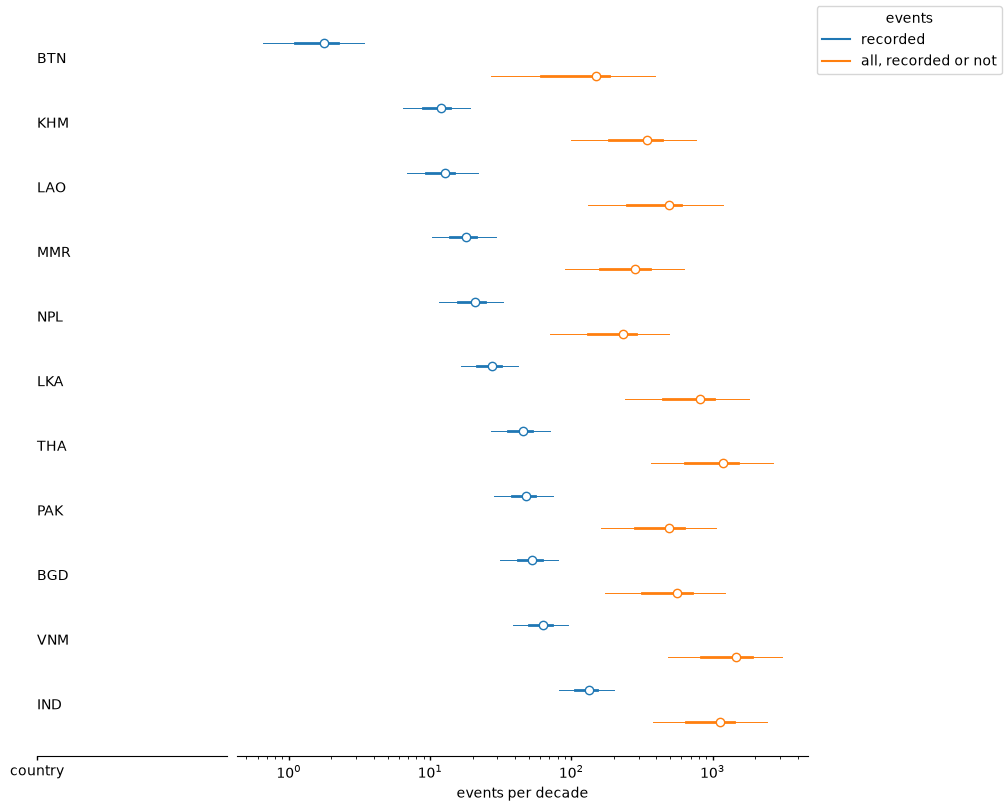

In [36]:
DECADE = 10

country_of_atom_label = xr.DataArray(np.array(COUNTRIES)[country_of_atom], dims="atom", name="country")
rate = np.exp(posterior["log_rate"])
level_share_of_atom = posterior["level_probability"].isel(country=xr.DataArray(country_of_atom, dims="atom")).drop_vars("country")
detection = (level_share_of_atom
             * posterior["naming_probability"].isel(unit=xr.DataArray(center_unit.reshape(len(LEVELS), n_atoms), dims=("level", "atom")))).sum("level")

per_decade = xr.concat([(rate * detection).groupby(country_of_atom_label).sum(),
                        rate.groupby(country_of_atom_label).sum()],
                       dim=pd.Index(["recorded", "all, recorded or not"], name="events")) * DECADE / YEARS
per_decade = per_decade.sortby(per_decade.sel(events="recorded").mean(("chain", "draw"))).transpose("chain", "draw", "country", "events")

forest = az.plot_forest(per_decade.to_dataset(name="events per decade"),
                        combined=True,
                        labels=["country"],
                        aes={"color": ["events"]},
                        figure_kwargs={"figsize": (10, 8)})
forest.add_legend("events")
# Recorded and total events differ by more than an order of magnitude, so both are read on a log scale.
interval_axis = forest.viz["figure"].item().axes[-1]
interval_axis.set_xscale("log")
interval_axis.set_xlabel("events per decade")
plt.show()

## Posterior predictive check

As in 13: a predictive model on the fit's `recorded_intensity`, with recorded events counted by country and year and split by reporting level within each country, drawn with `sample_posterior_predictive`.

In [37]:
def build_predictive_model():
    """The fitted model's recorded counts by country and year, and each country's split by reporting level."""
    with pm.Model(coords=COORDS) as model:
        recorded = recorded_intensity()
        recorded_by_country_level = pt.dot(atom_country, recorded.T)
        counts = annual_count(recorded_by_country_level.sum(axis=1))
        pm.Multinomial("level_count",
                       n=counts.sum(axis=1),
                       p=recorded_by_country_level / recorded_by_country_level.sum(axis=1, keepdims=True),
                       dims=("country", "level"))

    return model


with build_predictive_model():
    ppc = pm.sample_posterior_predictive(fit,
                                         var_names=["annual_count", "level_count"],
                                         random_seed=SEED)

ppc["observed_data"] = xr.Dataset({
    "annual_count": (("country", "year"), annual_observed),
    "level_count": (("country", "level"), record.groupby(["country", "level"]).size().unstack(fill_value=0).reindex(index=list(COUNTRIES), columns=list(LEVELS), fill_value=0).to_numpy()),
}, coords={"country": list(COUNTRIES), "year": years, "level": list(LEVELS)})

Sampling: [annual_count, level_count]


Output()

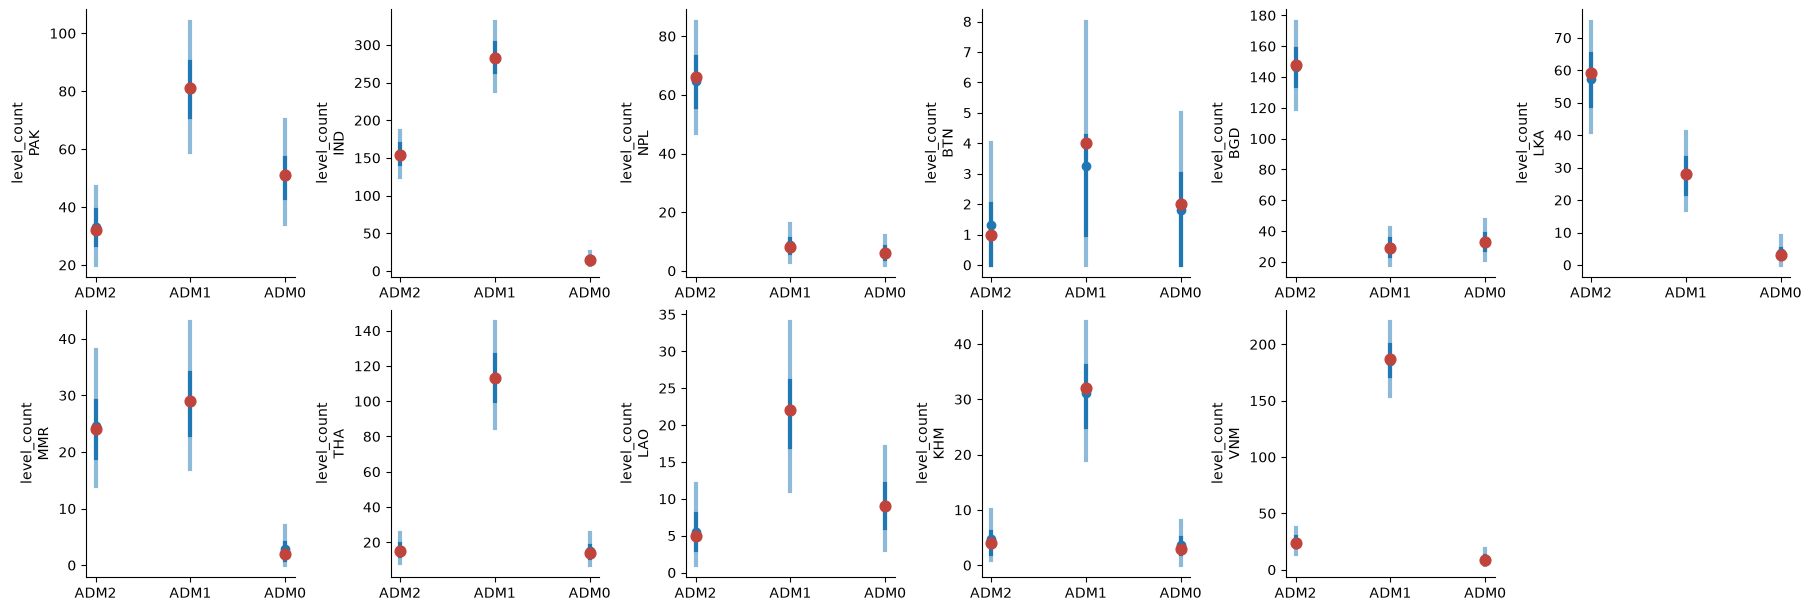

In [38]:
level_plot = az.plot_ppc_interval(ppc,
                                  var_names=["level_count"],
                                  visuals={"observed_markers": OBSERVED_MARKERS},
                                  cols=["country"],
                                  col_wrap=6,
                                  figure_kwargs={"figsize": (18, 6), "sharey": False})
for axis in level_plot.viz["figure"].item().axes:
    axis.set_xticks(np.arange(len(LEVELS)), list(LEVELS))
    axis.set_xlabel("")
plt.show()

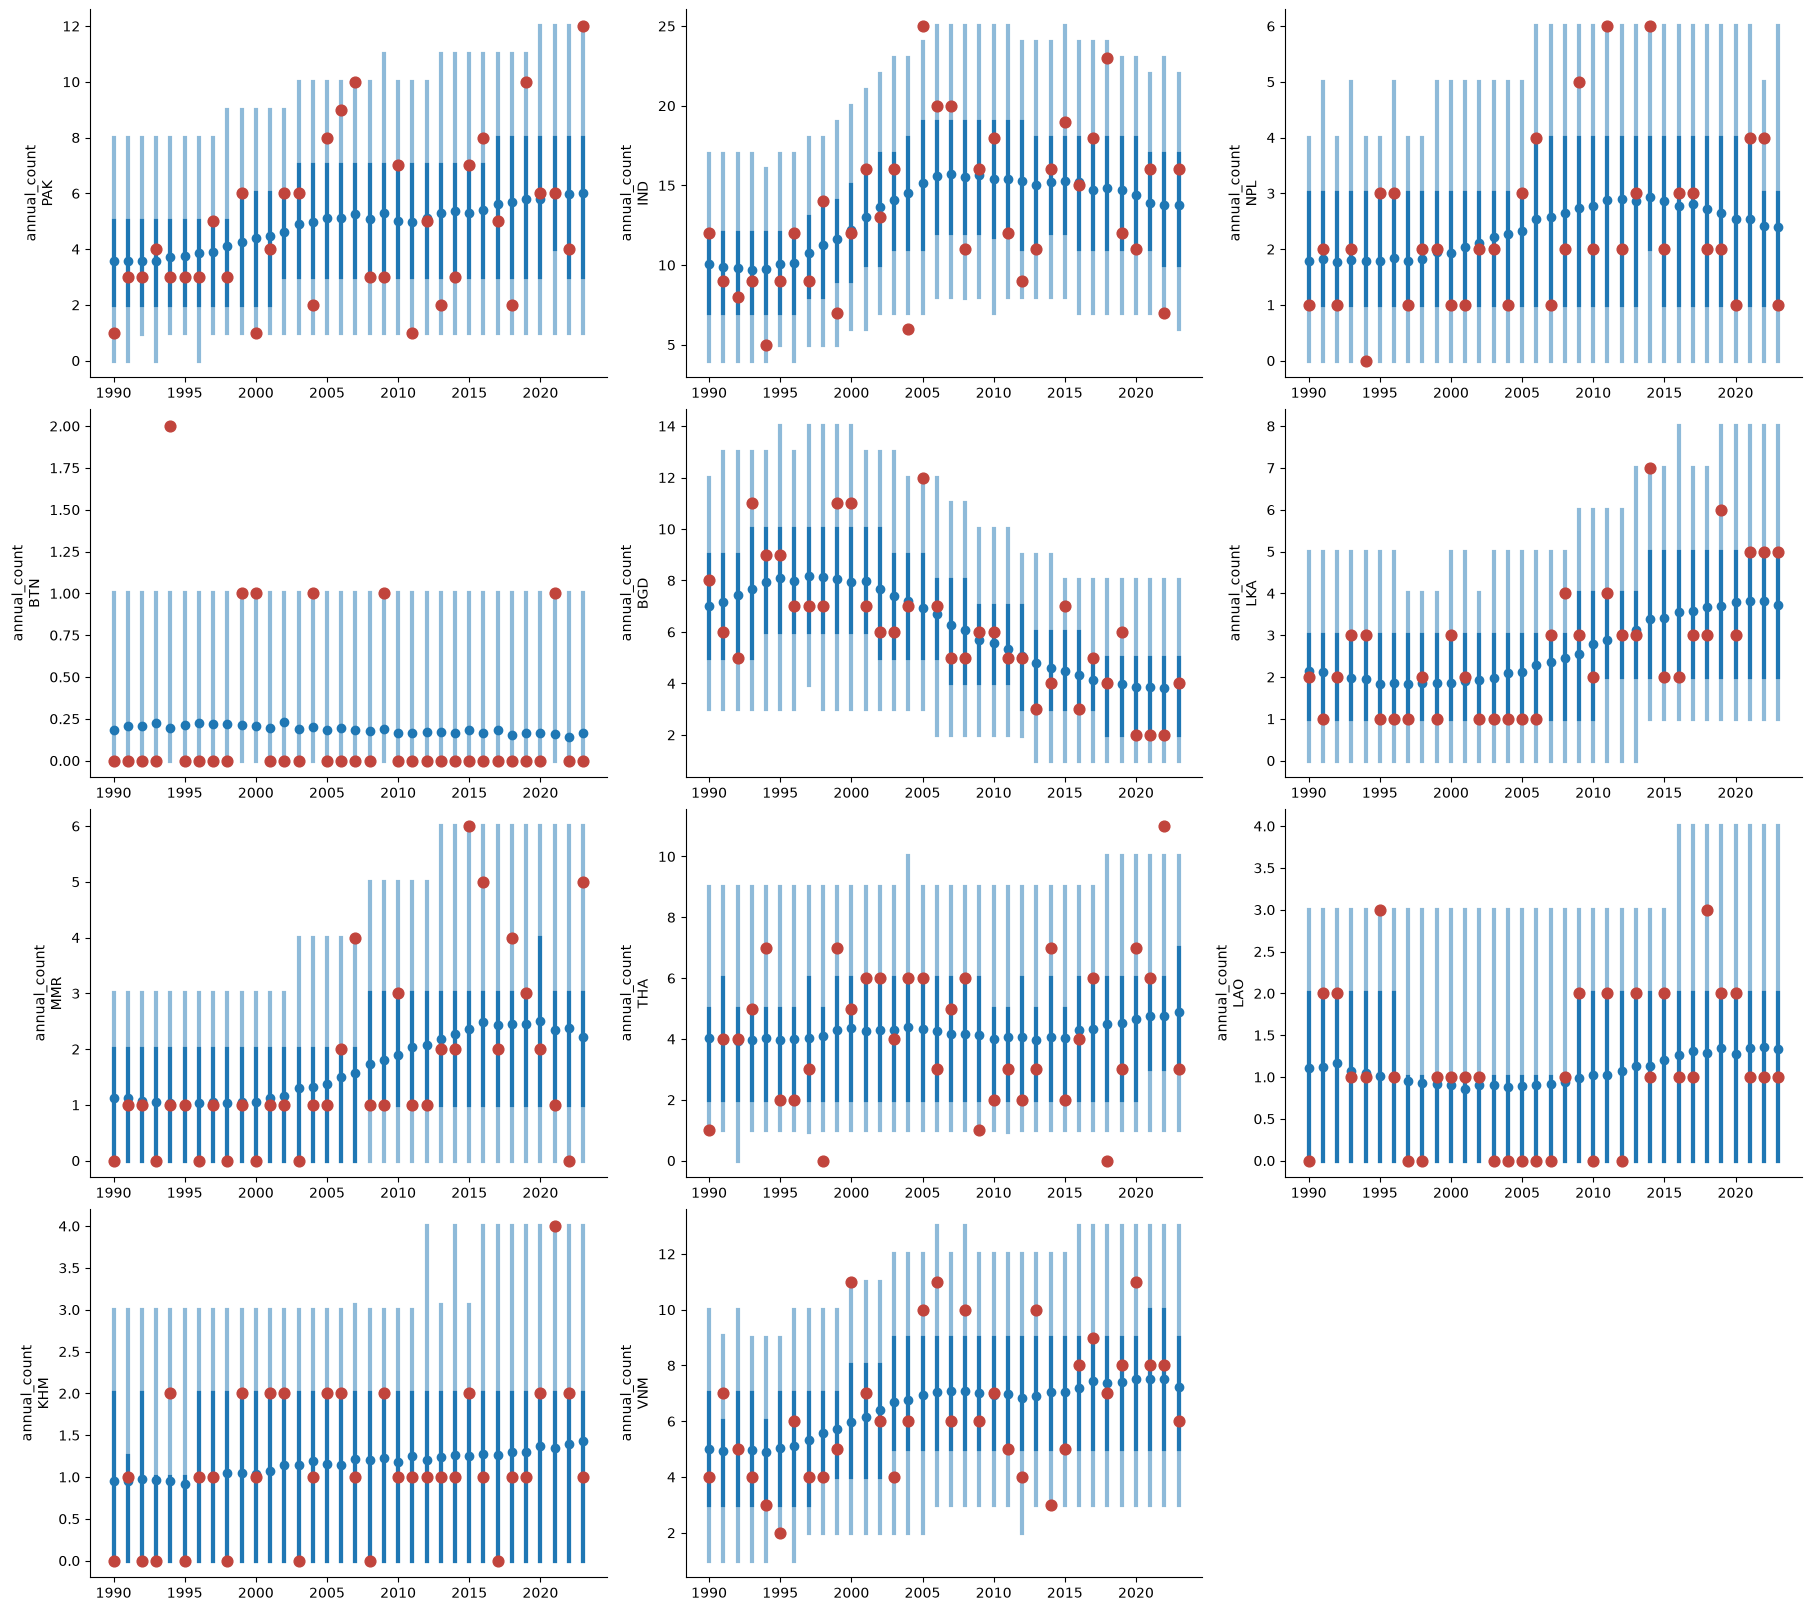

In [39]:
YEAR_TICK_STEP = 5

annual_plot = az.plot_ppc_interval(ppc,
                                   var_names=["annual_count"],
                                   visuals={"observed_markers": OBSERVED_MARKERS},
                                   cols=["country"],
                                   col_wrap=3,
                                   figure_kwargs={"figsize": (18, 16), "sharey": False})
for axis in annual_plot.viz["figure"].item().axes:
    axis.set_xticks(np.arange(0, YEARS, YEAR_TICK_STEP), years[::YEAR_TICK_STEP])
    axis.set_xlabel("")
plt.show()

## What the fit says

The fit took 27 minutes with nutpie's default diagonal mass matrix adaptation at a target acceptance of 0.8. The worst r-hat over every free parameter is 1.10, on one Thai district's offset, and among the global parameters 1.06, on the field's amplitude (bulk ESS 191) and the state offset scale (119). There are 18 divergences, 13 of them in one chain.

The hazard covariates are the best-determined part of the fit. Distance to a river has a slope of -0.99 (89% interval -1.21 to -0.78), close to India's -1.22. The product of distance and discharge is -0.37 (-0.59 to -0.17), so event centers fall off faster away from large rivers than from small ones, and discharge on its own is -0.39 (-0.73 to -0.06). Distance to the coast is -0.63 (-0.88 to -0.39). The field's lengthscale is 0.13 of the region's longer side (0.05 to 0.30), about 700 km, with an amplitude of 0.66 (0.20 to 1.18).

With each unit's population counted over every atom it overlaps and each country given its own level probabilities, detection rises with population again: the naming slope is 0.71 (0.35 to 1.09), weaker than India's 2.28 alone, and the naming intercept -3.05 (-3.94 to -2.10). The median district detection probability runs from 0.19 in Pakistan, whose 32 divisions hold millions each, to 0.02 in Bhutan, whose gewogs hold a few thousand. The level probabilities differ as GADM's levels do: about two thirds at ADM2 in Nepal, Bangladesh and Sri Lanka, three quarters or more at ADM1 in Thailand, Cambodia and Vietnam, and 0.43 at ADM0 in Pakistan. Every country's level split and 373 of 374 country-years fall inside their 94% predictive intervals. The district offset scale is 2.31 (2.04 to 2.59), still larger than India's 2.06.